# Brain Tumor MRI Dataset — Exploratory Data Analysis

**Dataset:** Jun Cheng Brain Tumor Dataset (Figshare)  
**Author:** Veda M V  
**Project:** Healthcare Image Classification  
**Date:** 23 November 2026

## Objectives
1. Examine the MRI dataset structure.
2. Analyze the distribution of the three tumor classes.
3. Inspect image dimensions and data quality.
4. Visualize representative MRI images.
5. Save EDA plots for the project report.

**Dataset source:** https://doi.org/10.6084/m9.figshare.1512427

In [1]:
from pathlib import Path

# Dataset directory
dataset_dir = Path("../data/raw/brain_tumor_dataset")

# Find MRI files
mat_files = sorted(dataset_dir.glob("*.mat"))

print("Total MATLAB files:", len(mat_files))
print("First 5 files:", [f.name for f in mat_files[:5]])

Total MATLAB files: 3065
First 5 files: ['1.mat', '10.mat', '100.mat', '1000.mat', '1001.mat']


In [2]:
import h5py

sample_file = dataset_dir / "1.mat"

with h5py.File(sample_file, "r") as f:
    print("File:", sample_file.name)
    print("Available keys:", list(f.keys()))

    if "cjdata" in f:
        print("\nFields inside cjdata:")
        print(list(f["cjdata"].keys()))

File: 1.mat
Available keys: ['cjdata']

Fields inside cjdata:
['PID', 'image', 'label', 'tumorBorder', 'tumorMask']


In [3]:
import h5py

print("h5py is ready!")

h5py is ready!


Image dimensions: (512, 512)
Tumor label: 1
Tumor type: Meningioma


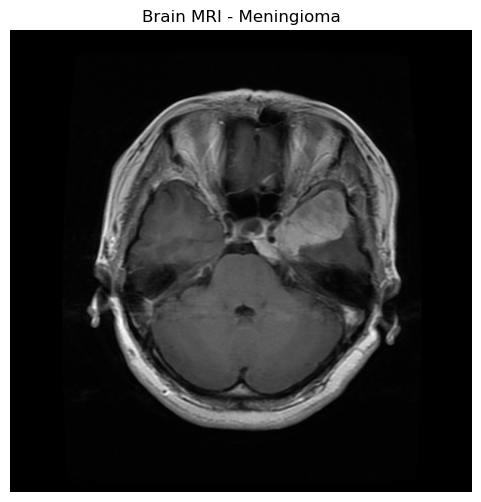

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import h5py

# Load the first MRI image
sample_file = dataset_dir / "1.mat"

with h5py.File(sample_file, "r") as f:
    image = np.array(f["cjdata"]["image"])
    label = int(np.array(f["cjdata"]["label"]).item())

# Map numeric labels to tumor names
tumor_classes = {
    1: "Meningioma",
    2: "Glioma",
    3: "Pituitary Tumor"
}

print("Image dimensions:", image.shape)
print("Tumor label:", label)
print("Tumor type:", tumor_classes.get(label, "Unknown"))

# Display the MRI
plt.figure(figsize=(6, 6))
plt.imshow(image.T, cmap="gray")
plt.title(f"Brain MRI - {tumor_classes.get(label, 'Unknown')}")
plt.axis("off")
plt.show()

In [5]:
%pip install "numpy==1.26.4"


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [6]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import h5py

print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("h5py:", h5py.__version__)
print("All imports successful!")


NumPy: 1.26.4
Matplotlib: 3.7.0
h5py: 3.12.1
All imports successful!


Total MRI images: 3064

Class distribution:
Meningioma: 708
Glioma: 1426
Pituitary Tumor: 930

Image dimensions:
(512, 512): 3049 images
(256, 256): 15 images

Unique patient identifiers: 233


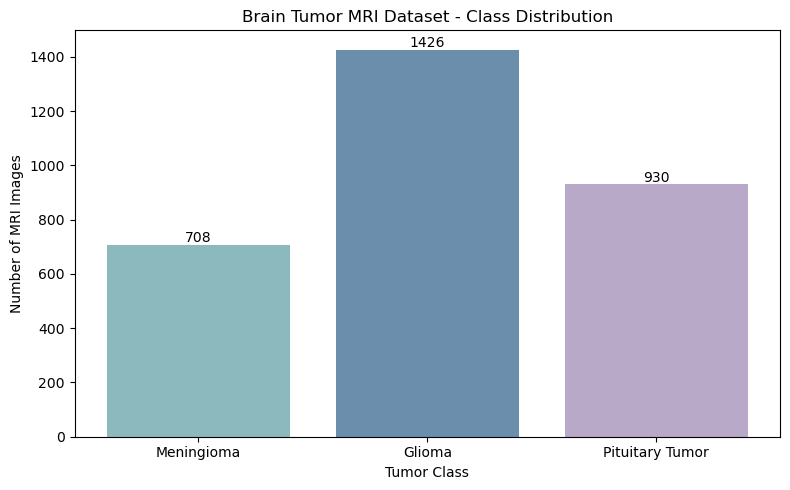

In [7]:
from collections import Counter
import h5py
import matplotlib.pyplot as plt

# Exclude the metadata file
mri_files = sorted(
    [f for f in mat_files if f.name != "cvind.mat"]
)

class_counts = Counter()
image_dimensions = Counter()
patient_ids = set()

for file_path in mri_files:
    with h5py.File(file_path, "r") as f:
        data = f["cjdata"]

        label = int(data["label"][()].item())
        dimensions = tuple(data["image"].shape)

        class_counts[label] += 1
        image_dimensions[dimensions] += 1

        # Patient IDs are useful for checking data leakage later
        pid = tuple(data["PID"][()].flatten().tolist())
        patient_ids.add(pid)

print("Total MRI images:", len(mri_files))

print("\nClass distribution:")
for label, name in tumor_classes.items():
    print(f"{name}: {class_counts[label]}")

print("\nImage dimensions:")
for dimensions, count in image_dimensions.items():
    print(f"{dimensions}: {count} images")

print("\nUnique patient identifiers:", len(patient_ids))

# Create class distribution chart
labels = [tumor_classes[i] for i in sorted(tumor_classes)]
counts = [class_counts[i] for i in sorted(tumor_classes)]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, counts, color=["#8CB9BD", "#6B8EAD", "#B8A9C9"])

for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        count + 10,
        str(count),
        ha="center"
    )

plt.title("Brain Tumor MRI Dataset - Class Distribution")
plt.xlabel("Tumor Class")
plt.ylabel("Number of MRI Images")
plt.tight_layout()
plt.show()

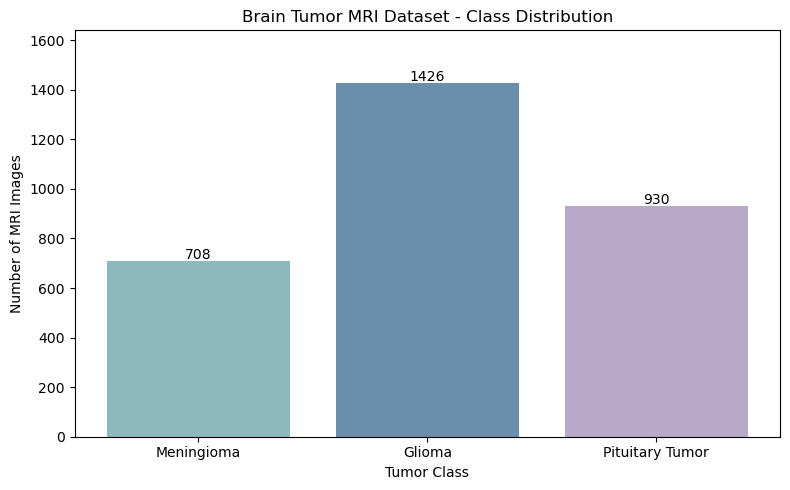

Chart saved to: C:\Users\vedav\OneDrive\Desktop\healthcare-image-classification\reports\figures\class_distribution.png


In [8]:
from pathlib import Path

# Create directory for EDA figures
figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

# Generate and save the class distribution chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    labels,
    counts,
    color=["#8CB9BD", "#6B8EAD", "#B8A9C9"]
)

for bar, count in zip(bars, counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        count + 10,
        str(count),
        ha="center"
    )

plt.title("Brain Tumor MRI Dataset - Class Distribution")
plt.xlabel("Tumor Class")
plt.ylabel("Number of MRI Images")
plt.ylim(0, max(counts) * 1.15)
plt.tight_layout()

output_path = figures_dir / "class_distribution.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", output_path.resolve())

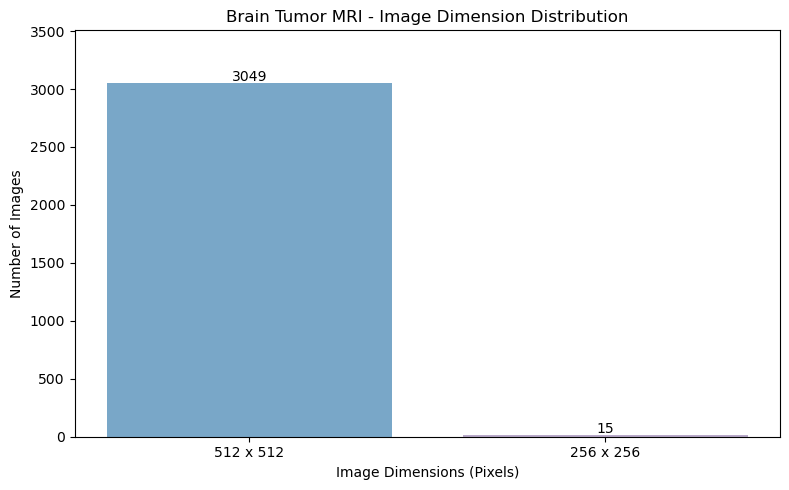

Chart saved to: C:\Users\vedav\OneDrive\Desktop\healthcare-image-classification\reports\figures\image_dimensions.png


In [9]:
# Image dimension distribution
dimension_labels = [
    f"{height} x {width}"
    for height, width in image_dimensions.keys()
]

dimension_counts = list(image_dimensions.values())

plt.figure(figsize=(8, 5))

bars = plt.bar(
    dimension_labels,
    dimension_counts,
    color=["#79A7C8", "#B8A9C9"]
)

for bar, count in zip(bars, dimension_counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        count + 20,
        str(count),
        ha="center"
    )

plt.title("Brain Tumor MRI - Image Dimension Distribution")
plt.xlabel("Image Dimensions (Pixels)")
plt.ylabel("Number of Images")
plt.ylim(0, max(dimension_counts) * 1.15)
plt.tight_layout()

# Save chart
output_path = figures_dir / "image_dimensions.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", output_path.resolve())

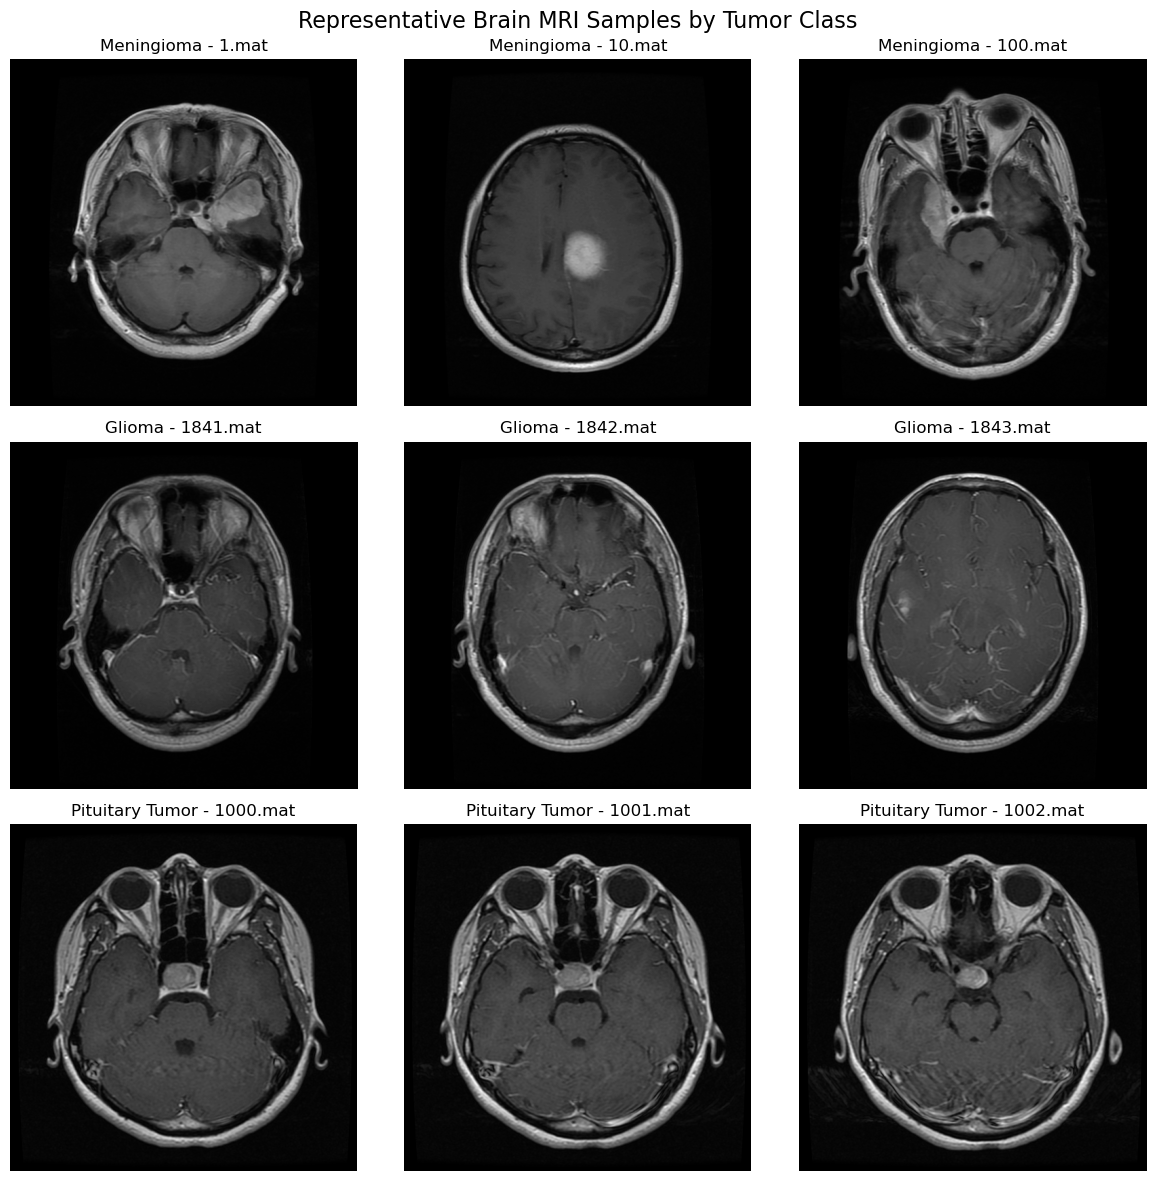

Chart saved to: C:\Users\vedav\OneDrive\Desktop\healthcare-image-classification\reports\figures\representative_mri_samples.png


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import h5py

# Collect three representative files from each class
samples = {1: [], 2: [], 3: []}

for file_path in mri_files:
    with h5py.File(file_path, "r") as f:
        label = int(f["cjdata"]["label"][()].item())

    if label in samples and len(samples[label]) < 3:
        samples[label].append(file_path)

    if all(len(files) == 3 for files in samples.values()):
        break

# Create a 3 x 3 image grid
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, (label, name) in enumerate(tumor_classes.items()):
    for col, file_path in enumerate(samples[label]):
        with h5py.File(file_path, "r") as f:
            image = np.array(f["cjdata"]["image"])

        axes[row, col].imshow(image.T, cmap="gray")
        axes[row, col].set_title(f"{name} - {file_path.name}")
        axes[row, col].axis("off")

plt.suptitle("Representative Brain MRI Samples by Tumor Class", fontsize=16)
plt.tight_layout()

# Save the visualization
output_path = figures_dir / "representative_mri_samples.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", output_path.resolve())


## EDA Findings and Observations

### 1. Dataset Overview
The Jun Cheng Brain Tumor MRI Dataset contains 3,064 MRI images from 233 patients, distributed across three tumor categories.

### 2. Class Distribution
- Meningioma: 708 images (23.1%)
- Glioma: 1,426 images (46.5%)
- Pituitary Tumor: 930 images (30.4%)

**Observation:** The dataset is moderately imbalanced, with Glioma being the most represented class and Meningioma the least represented.

### 3. Image Dimensions
- 3,049 images have dimensions of 512 × 512 pixels.
- 15 images have dimensions of 256 × 256 pixels.

**Observation:** Images must be resized to a consistent resolution during preprocessing.

### 4. Visual Inspection
Representative MRI images were successfully visualized for all three tumor classes.

**Observation:** MRI images show variations in tumor appearance, location, and image intensity.

### 5. Recommendations
- Use patient-level splitting to prevent data leakage.
- Resize images to a consistent resolution before model training.
- Normalize image intensities.
- Consider class weighting or balanced sampling to address class imbalance.
- Apply data augmentation only to the training set.

### 6. Limitations
The dataset contains only tumor-positive MRI images and cannot be used to distinguish healthy brains from tumor-positive brains.

This analysis is intended for research and educational purposes, not clinical diagnosis.


In [11]:
from pathlib import Path
import h5py
import numpy as np

data_dir = Path("../data/raw/brain_tumor_dataset")

image_files = [
    f for f in data_dir.glob("*.mat")
    if f.stem.isdigit()
]

issues = {
    "Unreadable files": [],
    "Missing required fields": [],
    "Invalid labels": [],
    "Empty images": [],
    "Constant images": [],
    "Non-finite pixel values": [],
    "Image-mask dimension mismatch": []
}

for file in image_files:
    try:
        with h5py.File(file, "r") as f:
            if "cjdata" not in f:
                issues["Missing required fields"].append(file.name)
                continue

            data = f["cjdata"]

            required = ["image", "label", "PID", "tumorMask"]

            if not all(key in data for key in required):
                issues["Missing required fields"].append(file.name)
                continue

            image = np.array(data["image"])
            label = np.array(data["label"]).flatten()
            mask = np.array(data["tumorMask"])

            if label.size != 1 or label[0] not in [1, 2, 3]:
                issues["Invalid labels"].append(file.name)

            if image.size == 0:
                issues["Empty images"].append(file.name)
            else:
                if np.min(image) == np.max(image):
                    issues["Constant images"].append(file.name)

                if not np.isfinite(image).all():
                    issues["Non-finite pixel values"].append(file.name)

            if image.shape != mask.shape:
                issues["Image-mask dimension mismatch"].append(file.name)

    except Exception:
        issues["Unreadable files"].append(file.name)

print("DATA QUALITY VALIDATION")
print("-" * 45)
print("Total image files:", len(image_files))

for check, files in issues.items():
    print(f"{check}: {len(files)}")
    if files:
        print("Affected files:", files[:10])

DATA QUALITY VALIDATION
---------------------------------------------
Total image files: 3064
Unreadable files: 0
Missing required fields: 0
Invalid labels: 0
Empty images: 0
Constant images: 0
Non-finite pixel values: 0
Image-mask dimension mismatch: 0


## Data Quality Validation

Date: 24 November 2026

All 3,064 MRI image files were checked for data quality
and structural consistency.

### Validation Results

- Unreadable files: 0
- Missing required fields: 0
- Invalid labels: 0
- Empty images: 0
- Constant images: 0
- Non-finite pixel values: 0
- Image-mask dimension mismatches: 0

### Conclusion

All 3,064 MRI images passed the implemented validation
checks. No issues requiring image removal were identified
during this validation.

The dataset is suitable for proceeding to the planned
preprocessing stage based on these checks.

Duplicate detection and patient-level leakage verification
remain separate validation tasks.

The original raw dataset remains unchanged.